# Combined-city dark-store area segmentation

One combined eight-metro dataset, one fitted scaler/PCA and one KMeans model with a shared K. Following the customer-segmentation reference: inspect data, scale features, reduce dimensions, cluster, profile and rank. City names and coordinates are not clustering inputs. Geographic training/test labels support evaluation only; no city-specific models are fitted.

Run all cells from this folder. Source dates and limitations are in data/sources.json. The notebook starts from the frozen feature dataset, not remote raw-data ingestion.

Eight inputs: density, 2 km population, food, education, healthcare, retail, transit and competitors. Three components are retained if they explain ≥90% of transformed training variance, otherwise four. No invented traffic, rents or isochrones. K=4 is fixed for finer, user-requested segmentation across all cities. K=2–6 silhouette and elbow diagnostics remain visible; the diagnostic preference is reported separately rather than calling four optimal. Every selected cluster must contain at least 2% of training rows. Cluster priority is a declared business rule, not a learned profit outcome.

In [1]:
from pathlib import Path
import json, hashlib, io, base64, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import BallTree
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, roc_auc_score, average_precision_score)
import joblib

ROOT = Path.cwd()
assert (ROOT / 'data/metro_features.csv').exists(), 'Run this notebook from the Metro-PCA-KMeans folder.'
for folder in ['reports', 'model', 'guide']:
    (ROOT / folder).mkdir(exist_ok=True)
SEED = 42
FEATURES = ['population_density_km2', 'population_2km_est', 'food_pois_2km',
            'education_pois_2km', 'healthcare_pois_2km', 'retail_pois_2km',
            'transit_objects_2km', 'competitor_stores_2km']
# Business assumptions, fixed before loading Blinkit reference locations.
PRIORITY_WEIGHTS = np.array([.25, .25, .10, .05, .05, .10, .10, .10])
K_VALUES = range(2, 7)
PCA_TARGET = .90
BLOCK_KM, BUFFER_KM, TEST_FRACTION = 12, 4, .20
N_SITES, SPACING_KM, RANDOM_REPEATS, STABILITY_REPEATS = 20, 1.5, 100, 5
R = 6371.0088
CITIES = {'Bengaluru':(12.9716,77.5946,30), 'Delhi NCR':(28.6139,77.2090,50),
          'Mumbai':(19.1,72.95,40), 'Kolkata':(22.5726,88.3639,30),
          'Chennai':(13.04,80.23,30), 'Hyderabad':(17.385,78.4867,30),
          'Pune':(18.5204,73.8567,30), 'Ahmedabad':(23.0225,72.5714,30)}
df = pd.read_csv(ROOT / 'data/metro_features.csv')
sources = json.loads((ROOT / 'data/sources.json').read_text())
assert len(df) == 29941 and df.city.nunique() == 8 and df.zone_id.is_unique
assert df[FEATURES].notna().all().all() and np.isfinite(df[FEATURES]).all().all()
assert (df[FEATURES] >= 0).all().all()
assert not any('blinkit' in x for x in FEATURES)
print('Dataset:', df.shape, '\nEight default inputs:', FEATURES)
display(df.groupby('city')[FEATURES].median().round(1))

Dataset: (29941, 19) 
Eight default inputs: ['population_density_km2', 'population_2km_est', 'food_pois_2km', 'education_pois_2km', 'healthcare_pois_2km', 'retail_pois_2km', 'transit_objects_2km', 'competitor_stores_2km']


,population_density_km2,population_2km_est,food_pois_2km,education_pois_2km,healthcare_pois_2km,retail_pois_2km,transit_objects_2km,competitor_stores_2km
city,,,,,,,,
Ahmedabad,839.2,13118.9,0.0,0.0,0.0,0.0,0.0,0.0
Bengaluru,1548.2,19294.4,1.0,3.0,0.0,0.0,10.0,0.0
Chennai,2451.2,30100.2,0.0,2.0,1.0,0.0,3.0,0.0
Delhi NCR,1737.8,25671.5,0.0,0.0,0.0,0.0,0.0,0.0
Hyderabad,1479.2,23057.2,0.0,1.0,0.0,0.0,0.0,0.0
Kolkata,3277.2,46453.0,0.0,0.0,0.0,0.0,0.0,0.0
Mumbai,1546.1,29462.9,0.0,0.0,0.0,0.0,1.0,0.0
Pune,1189.0,19058.8,0.0,0.0,0.0,0.0,0.0,0.0


# Explore the dataset



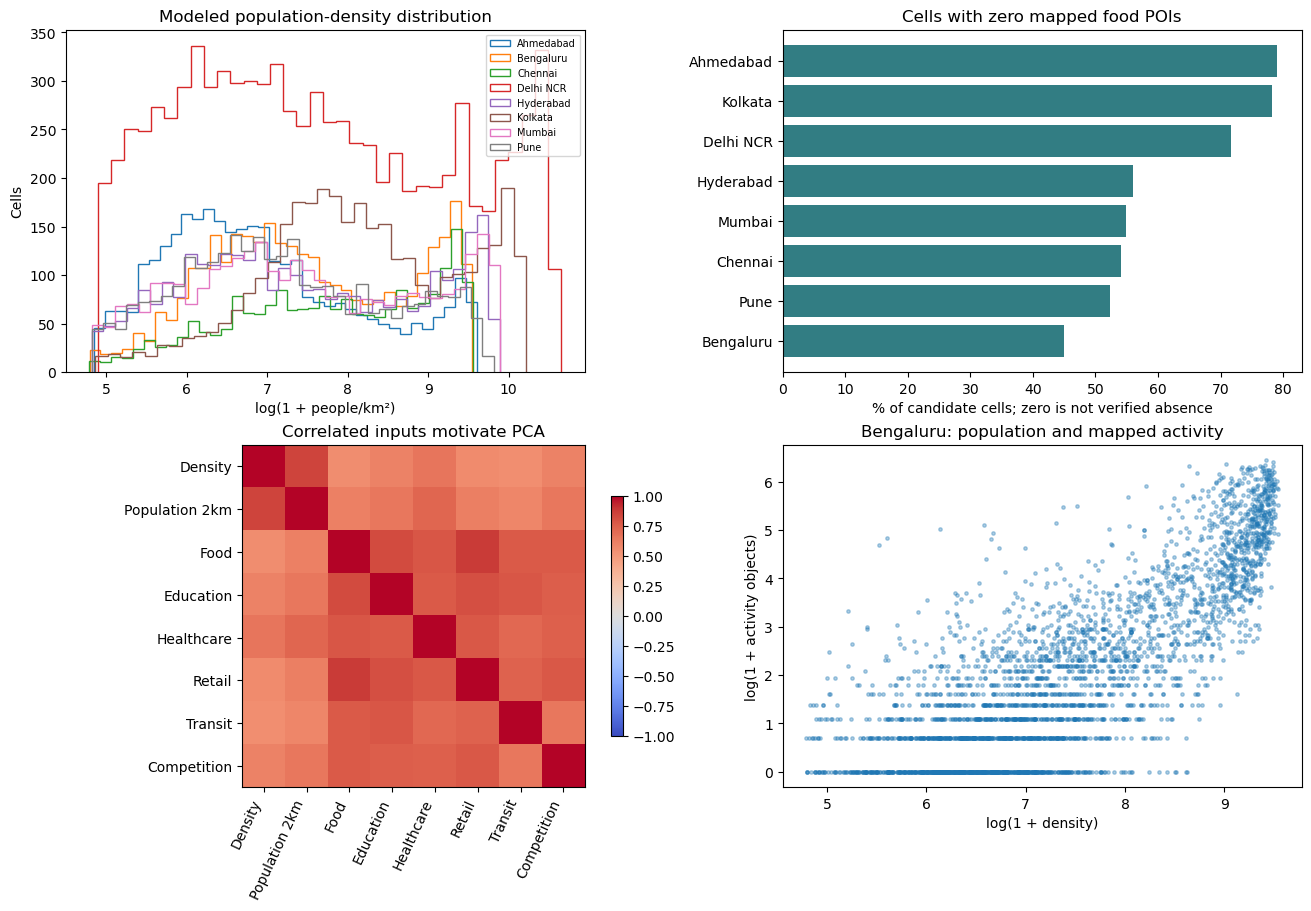

In [2]:
# Descriptive EDA only: full-data plots never fit preprocessing or select model parameters.
fig, ax = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for city, part in df.groupby('city'):
    ax[0,0].hist(np.log1p(part.population_density_km2), bins=35, histtype='step', label=city)
ax[0,0].set(title='Modeled population-density distribution', xlabel='log(1 + people/km²)', ylabel='Cells')
ax[0,0].legend(fontsize=7)
zero = df.groupby('city').food_pois_2km.apply(lambda s: 100 * (s == 0).mean()).sort_values()
ax[0,1].barh(zero.index, zero.values, color='#327d83')
ax[0,1].set(title='Cells with zero mapped food POIs', xlabel='% of candidate cells; zero is not verified absence')
corr = np.log1p(df[FEATURES]).corr()
labels = ['Density','Population 2km','Food','Education','Healthcare','Retail','Transit','Competition']
im=ax[1,0].imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax[1,0].set_xticks(range(8), labels, rotation=65, ha='right'); ax[1,0].set_yticks(range(8),labels)
ax[1,0].set_title('Correlated inputs motivate PCA'); fig.colorbar(im, ax=ax[1,0], shrink=.7)
b=df[df.city=='Bengaluru']
ax[1,1].scatter(np.log1p(b.population_density_km2), np.log1p(b.activity_pois_2km), s=6, alpha=.35)
ax[1,1].set(title='Bengaluru: population and mapped activity', xlabel='log(1 + density)', ylabel='log(1 + activity objects)')
fig.savefig(ROOT/'reports/eda.png', dpi=140); plt.show()

# Prepare features and evaluation helpers



In [3]:
def coordinates(frame):
    return frame[['latitude','longitude']].to_numpy()

def geo_distance(point, points):
    a,b=np.radians(point),np.radians(points)
    delta=b-a
    return 2*R*np.arcsin(np.minimum(1,np.sqrt(np.sin(delta[:,0]/2)**2 + np.cos(a[0])*np.cos(b[:,0])*np.sin(delta[:,1]/2)**2)))

def nearest(points, references):
    if not len(references): return np.full(len(points),np.nan)
    return BallTree(np.radians(references),metric='haversine').query(np.radians(points),k=1)[0][:,0]*R

def block_ids(points, city):
    lat,lon,_=CITIES[city]
    x=R*np.cos(np.radians(lat))*np.radians(points[:,1]-lon)
    y=R*np.radians(points[:,0]-lat)
    return np.array([f'{int(a)}:{int(b)}' for a,b in zip(np.floor(x/BLOCK_KM),np.floor(y/BLOCK_KM))])

def spatial_split(part, city, seed):
    xy=coordinates(part); blocks=block_ids(xy,city); unique=np.unique(blocks)
    rng=np.random.default_rng(seed)
    held=set(rng.choice(unique,size=max(2,int(np.ceil(len(unique)*TEST_FRACTION))),replace=False))
    test=np.array([b in held for b in blocks])
    separation=nearest(xy,xy[test])
    train=(~test)&(separation>BUFFER_KM)
    assert train.sum()>=200 and test.sum()>=100
    assert nearest(xy[train],xy[test]).min()>BUFFER_KM
    return train,test,held,blocks

def fit_preprocessing(raw, fixed_components=None):
    # Fit every learned preprocessing quantity on training data only.
    lower,upper=np.quantile(raw,[.01,.99],axis=0)
    log_values=np.log1p(np.clip(raw,lower,upper))
    scaler=StandardScaler().fit(log_values)
    z=scaler.transform(log_values)
    pca=PCA(svd_solver='full').fit(z)
    cumulative=np.cumsum(pca.explained_variance_ratio_)
    n=fixed_components or (3 if cumulative[2]>=PCA_TARGET else 4)
    prep={'lower':lower,'upper':upper,'scaler':scaler,'pca':pca,'n_components':n}
    return prep,pca.transform(z)[:,:n],cumulative

def transform(raw,prep):
    z=prep['scaler'].transform(np.log1p(np.clip(raw,prep['lower'],prep['upper'])))
    return prep['pca'].transform(z)[:,:prep['n_components']]

def priority_utility(raw, reference):
    # Training empirical percentiles. Competition is inverted; all others positive.
    values=[]
    for j in range(raw.shape[1]):
        ref=np.sort(reference[:,j]); x=raw[:,j]
        p=(np.searchsorted(ref,x,side='left')+np.searchsorted(ref,x,side='right'))/(2*len(ref))
        values.append(1-p if j==7 else p)
    return np.column_stack(values)@PRIORITY_WEIGHTS

def priority_labels(utilities):
    k=len(utilities)
    words={2:['Lower','Higher'],3:['Lower','Medium','Higher'],
           4:['Lower','Medium','High','Very high'],
           5:['Lower','Moderate-low','Medium','High','Very high'],
           6:['Lower','Moderate-low','Medium','Moderate-high','High','Very high']}[k]
    return {int(c):words[rank]+' priority' for rank,c in enumerate(np.argsort(utilities))}

def potential_score(X,model,utilities,temperature):
    # Smooth distance-weighted cluster utilities. A screening index, not probability.
    affinities=softmax(-(model.transform(X)**2)/(2*temperature**2),axis=1)
    return 100*(affinities@utilities)

def separation_metrics(X,labels):
    if len(np.unique(labels))<2:return np.nan,np.nan
    return (silhouette_score(X,labels,sample_size=min(1000,len(X)),random_state=SEED),
            davies_bouldin_score(X,labels))

def shortlist(xy,scores,n=N_SITES):
    chosen=[]
    for i in np.argsort(-scores,kind='stable'):
        if not chosen or np.all(geo_distance(xy[i],xy[chosen])>=SPACING_KM):chosen.append(int(i))
        if len(chosen)>=n:break
    return np.array(chosen,dtype=int)

# One pooled PCA → one pooled KMeans → cluster priorities



In [4]:
# Combine training geography from ALL eight cities before fitting anything.
parts=[]; test_blocks={}
for ci,city in enumerate(CITIES):
    part=df[df.city==city].copy().reset_index(drop=True)
    train,test,held,blocks=spatial_split(part,city,SEED+ci)
    part['split']=np.where(test,'test',np.where(train,'train','buffer_excluded'))
    part['spatial_block']=blocks
    parts.append(part);test_blocks[city]=sorted(held)
assigned=pd.concat(parts,ignore_index=True)
raw=assigned[FEATURES].to_numpy(float)
train=assigned.split.eq('train').to_numpy(); test=assigned.split.eq('test').to_numpy()
prep,Xtrain,cumulative=fit_preprocessing(raw[train])
Xtest=transform(raw[test],prep)
pca_table=pd.DataFrame({'component':np.arange(1,9),'variance_ratio':prep['pca'].explained_variance_ratio_,'cumulative_variance':cumulative})
display(pca_table)
print('ONE pooled PCA:',prep['n_components'],'components; retained variance:',cumulative[prep['n_components']-1])
trials=[];fits={}
for k in K_VALUES:
    km=KMeans(n_clusters=k,random_state=SEED,n_init=20).fit(Xtrain)
    sil,db=separation_metrics(Xtrain,km.labels_)
    share=np.bincount(km.labels_,minlength=k).min()/len(Xtrain)
    trials.append({'k':k,'silhouette':sil,'inertia':km.inertia_,'minimum_cluster_share':share})
    fits[k]=km
selection=pd.DataFrame(trials)
eligible=selection[selection.minimum_cluster_share>=.02]
diagnostic_k=int(eligible.loc[eligible.silhouette>=eligible.silhouette.max()-.02,'k'].min())
# User-requested granularity: four shared segments, fixed before this rerun.
K=4
assert float(selection.loc[selection.k.eq(K),'minimum_cluster_share'].iloc[0])>=.02
km=fits[K]
selection['selected']=selection.k.eq(K)
selection['silhouette_rule_choice']=selection.k.eq(diagnostic_k)
# One shared cluster meaning and one shared priority rule across every city.
utility=priority_utility(raw[train],raw[train])
utilities=np.array([utility[km.labels_==i].mean() for i in range(K)])
names=priority_labels(utilities)
temperature=max(float(np.median(km.transform(Xtrain).min(axis=1))),.1)
Xall=transform(raw,prep)
assigned['cluster']=km.predict(Xall)
assigned['priority']=assigned.cluster.map(names)
assigned['potential_index']=potential_score(Xall,km,utilities,temperature)
assigned['potential_rank_in_city']=assigned.groupby('city').potential_index.rank(method='first',ascending=False).astype(int)
profiles=assigned.loc[train].groupby('cluster')[FEATURES].mean().reset_index()
profiles['priority']=profiles.cluster.map(names)
profiles['priority_score']=100*utilities
profiles['training_areas']=np.bincount(km.labels_,minlength=K)
profiles=profiles.sort_values('priority_score',ascending=False)
profiles.insert(0,'priority_rank',range(1,K+1))
city_clusters=pd.crosstab(assigned.city,assigned.priority)
loadings=pd.DataFrame(prep['pca'].components_[:prep['n_components']].T,index=FEATURES,columns=[f'PC{i+1}' for i in range(prep['n_components'])])
ari=[]
for repeat in range(STABILITY_REPEATS):
    ix=np.random.default_rng(SEED+repeat).choice(len(Xtrain),int(.8*len(Xtrain)),replace=False)
    p2,x2,_=fit_preprocessing(raw[train][ix],fixed_components=prep['n_components'])
    m2=KMeans(n_clusters=K,n_init=10,random_state=SEED+repeat).fit(x2)
    ari.append(adjusted_rand_score(km.predict(Xtest),m2.predict(transform(raw[test],p2))))
held_sil,held_db=separation_metrics(Xtest,km.predict(Xtest))
global_model={'preprocessing':prep,'kmeans':km,'features':FEATURES,'priority_utilities':utilities,'priority_labels':names,'temperature':temperature,'training_reference':raw[train],'test_blocks_by_city':test_blocks}
# These dictionaries only supply city evaluation metadata; every entry references the SAME model.
artifacts={city:{**global_model,'test_blocks':test_blocks[city]} for city in CITIES}
joblib.dump(global_model,ROOT/'model/global_model.joblib')
assigned.to_csv(ROOT/'model/area_assignments.csv',index=False)
profiles.to_csv(ROOT/'reports/cluster_ranking.csv',index=False)
print('ONE pooled KMeans; K =',K,'held-out silhouette =',held_sil,'mean stability ARI =',np.mean(ari))
display(selection);display(profiles);display(city_clusters);display(loadings)

ONE pooled PCA: 4 components; retained variance: 0.9169516031432794
ONE pooled KMeans; K = 4 held-out silhouette = 0.41667868425951354 mean stability ARI = 0.9925179115508165


,component,variance_ratio,cumulative_variance
0,1,0.735646,0.735646
1,2,0.106074,0.841720
2,3,0.044384,0.886105
3,4,0.030847,0.916952
4,5,0.027582,0.944533
5,6,0.022953,0.967486
6,7,0.017785,0.985271
7,8,0.014729,1.000000


,k,silhouette,inertia,minimum_cluster_share,selected,silhouette_rule_choice
0,2,0.613693,45824.150805,0.232749,False,True
1,3,0.437802,31764.117064,0.169310,False,False
2,4,0.375831,25079.527027,0.116404,True,False
3,5,0.385911,21912.925211,0.100722,False,False
4,6,0.345526,19362.871571,0.094212,False,False


,priority_rank,cluster,population_density_km2,population_2km_est,food_pois_2km,education_pois_2km,healthcare_pois_2km,retail_pois_2km,transit_objects_2km,competitor_stores_2km,priority,priority_score,training_areas
1,1,1,15040.027560,180174.635037,50.423996,28.735130,22.592781,18.651246,43.191154,3.820031,Very high priority,81.113345,1967
0,2,0,10539.934511,131892.243712,4.959745,6.828617,7.847748,2.980470,9.389000,1.872858,High priority,70.729958,2509
3,3,3,4707.889041,57680.984829,0.506058,1.119750,1.064015,0.224960,1.863489,0.180533,Medium priority,53.949863,4952
2,4,2,750.296837,13174.465629,0.178179,0.345248,0.107631,0.031593,0.983400,0.012584,Lower priority,32.226087,7470


priority,High priority,Lower priority,Medium priority,Very high priority
city,,,,
Ahmedabad,349,2309,583,61
Bengaluru,482,1434,610,738
Chennai,443,735,515,343
Delhi NCR,1170,4273,2407,801
Hyderabad,491,1578,609,465
Kolkata,490,853,1929,169
Mumbai,442,1434,687,559
Pune,428,1670,550,334


,PC1,PC2,PC3,PC4
population_density_km2,0.314893,0.625414,0.157231,0.049140
population_2km_est,0.329787,0.573693,0.039882,-0.032386
food_pois_2km,0.370246,-0.309644,-0.079292,-0.240613
education_pois_2km,0.371060,-0.201672,0.141013,0.155375
healthcare_pois_2km,0.368759,0.024855,-0.153139,-0.584785
retail_pois_2km,0.368863,-0.268752,-0.179355,-0.245666
transit_objects_2km,0.343817,-0.260893,0.729471,0.289853
competitor_stores_2km,0.356458,-0.047666,-0.599807,0.654339


# Compare recommendations with real mapped stores



In [5]:
# Reference data are first opened after preprocessing, K choice, and priority rules are frozen.
ref=pd.read_csv(ROOT/'data/blinkit_reference.csv')
ref=ref.drop_duplicates('id').drop_duplicates(['lat','lon'])
ref=ref[ref.accuracy_m.isna() | (ref.accuracy_m<=100)]
alignment=[]; baselines=[]; random_ranges=[]; shortlists=[]; reference_counts=[]
distance_records={m:[] for m in ['PCA_KMeans','Population_only','Uncompressed_rule']}
test_store_points={}

def evaluate_ranked(xy,scores,stores):
    chosen=shortlist(xy,scores)
    if not len(stores):
        return {'n_shortlisted':len(chosen),'hit_500m':np.nan,'hit_1km':np.nan,'hit_2km':np.nan,
                'store_coverage_2km':np.nan,'median_distance_km':np.nan,
                'reference_auroc':np.nan,'reference_average_precision':np.nan,'reference_positive_prevalence':np.nan},chosen
    distance_to_store=nearest(xy,stores)
    target=(distance_to_store<=1).astype(int)
    both=len(np.unique(target))==2
    result={'n_shortlisted':len(chosen),'hit_500m':float((distance_to_store[chosen]<=.5).mean()),
      'hit_1km':float((distance_to_store[chosen]<=1).mean()),'hit_2km':float((distance_to_store[chosen]<=2).mean()),
      'store_coverage_2km':float((nearest(stores,xy[chosen])<=2).mean()),
      'median_distance_km':float(np.median(distance_to_store[chosen])),
      'reference_auroc':roc_auc_score(target,scores) if both else np.nan,
      'reference_average_precision':average_precision_score(target,scores) if both else np.nan,
      'reference_positive_prevalence':float(target.mean())}
    return result,chosen

for ci,city in enumerate(CITIES):
    test=assigned[(assigned.city==city)&(assigned.split=='test')].copy().reset_index(drop=True)
    xy=coordinates(test); bundle=artifacts[city]
    lat,lon,radius=CITIES[city]
    within=geo_distance([lat,lon],ref[['lat','lon']].to_numpy())<=radius
    city_ref=ref[within].copy()
    in_test=np.array([b in bundle['test_blocks'] for b in block_ids(city_ref[['lat','lon']].to_numpy(),city)])
    stores=city_ref.loc[in_test,['lat','lon']].to_numpy()
    test_store_points[city]=stores
    reference_counts.append({'city':city,'mapped_stores_in_window':len(city_ref),'mapped_stores_in_test_blocks':len(stores)})
    # Baselines are evaluated on exactly the same test candidates and store reference.
    methods={'PCA_KMeans':test.potential_index.to_numpy(),
             'Population_only':test.population_density_km2.to_numpy(),
             'Uncompressed_rule':priority_utility(test[FEATURES].to_numpy(),bundle['training_reference'])}
    for method,score in methods.items():
        result,chosen=evaluate_ranked(xy,score,stores)
        distance_records[method].append(nearest(xy[chosen],stores))
        baselines.append({'city':city,'method':method,'test_reference_stores':len(stores),**result})
        if method=='PCA_KMeans':
            alignment.append({'city':city,'test_reference_stores':len(stores),**result})
            shortlist_frame=test.iloc[chosen][['city','zone_id','latitude','longitude','priority','potential_index']].copy()
            shortlist_frame['rank']=range(1,len(chosen)+1)
            shortlist_frame['nearest_test_reference_km']=nearest(xy[chosen],stores)
            shortlists.append(shortlist_frame)
    rng=np.random.default_rng(SEED+ci)
    null=[]
    # Store-distance matrix reused; 100 random spatially separated shortlists.
    if len(stores):
        d=nearest(xy,stores)
        for _ in range(RANDOM_REPEATS):
            indices=shortlist(xy,rng.random(len(xy)))
            null.append(float((d[indices]<=1).mean()))
    random_ranges.append({'city':city,'random_hit_1km_mean':np.mean(null) if null else np.nan,
       'random_hit_1km_p025':np.quantile(null,.025) if null else np.nan,
       'random_hit_1km_p975':np.quantile(null,.975) if null else np.nan})
    print(city,'test stores:',len(stores),'model hit@1km:',round(alignment[-1]['hit_1km'],3),flush=True)
alignment=pd.DataFrame(alignment).merge(pd.DataFrame(random_ranges),on='city')
alignment['lift_vs_random']=alignment.hit_1km/alignment.random_hit_1km_mean.replace(0,np.nan)
baselines=pd.DataFrame(baselines)
shortlist_results=pd.concat(shortlists,ignore_index=True)
reference_counts=pd.DataFrame(reference_counts)
alignment.to_csv(ROOT/'reports/evaluation.csv',index=False)
display(baselines[['city','method','test_reference_stores','hit_1km','store_coverage_2km','reference_auroc','reference_average_precision']].round(3))

Bengaluru test stores: 8 model hit@1km: 0.1
Delhi NCR test stores: 71 model hit@1km: 0.85
Mumbai test stores: 43 model hit@1km: 0.7
Kolkata test stores: 9 model hit@1km: 0.3
Chennai test stores: 11 model hit@1km: 0.25
Hyderabad test stores: 30 model hit@1km: 0.6
Pune test stores: 23 model hit@1km: 0.6
Ahmedabad test stores: 9 model hit@1km: 0.3


,city,method,test_reference_stores,hit_1km,store_coverage_2km,reference_auroc,reference_average_precision
0,Bengaluru,PCA_KMeans,8,0.10,0.875,0.955,0.485
1,Bengaluru,Population_only,8,0.20,0.875,0.887,0.419
2,Bengaluru,Uncompressed_rule,8,0.25,0.875,0.950,0.470
3,Delhi NCR,PCA_KMeans,71,0.85,0.577,0.945,0.728
4,Delhi NCR,Population_only,71,0.85,0.563,0.907,0.586
5,Delhi NCR,Uncompressed_rule,71,0.65,0.394,0.929,0.556
6,Mumbai,PCA_KMeans,43,0.70,0.674,0.925,0.696
7,Mumbai,Population_only,43,0.70,0.791,0.904,0.623
8,Mumbai,Uncompressed_rule,43,0.90,0.744,0.927,0.687
9,Kolkata,PCA_KMeans,9,0.30,1.000,0.952,0.532


# Visualize clusters and location alignment



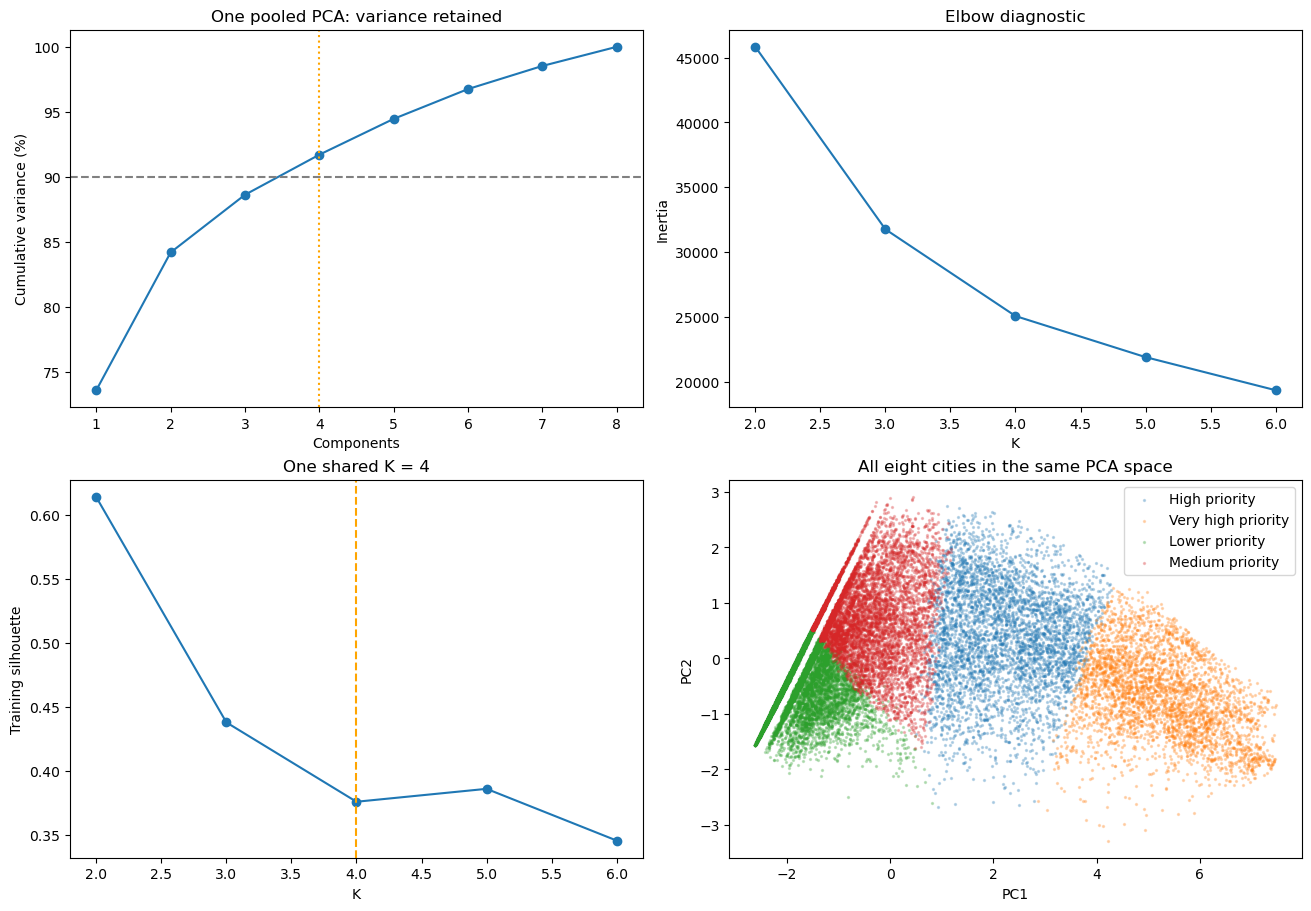

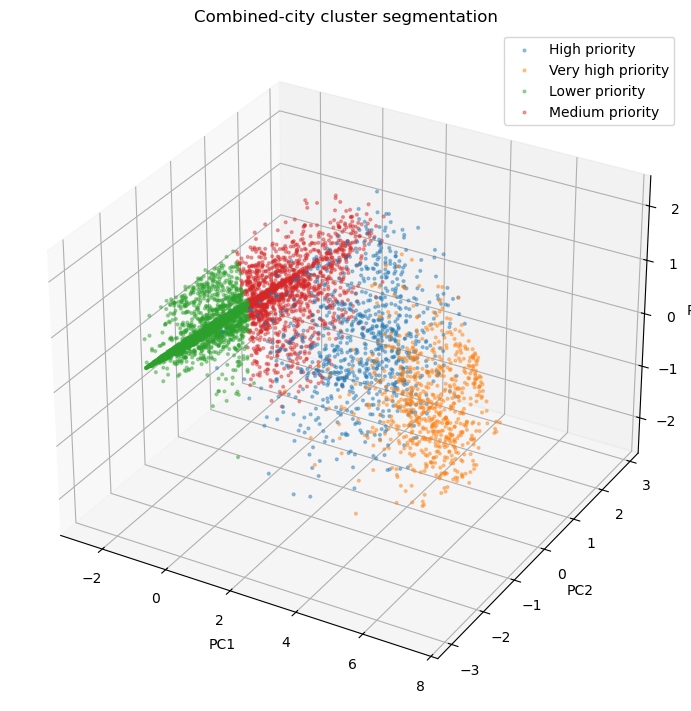

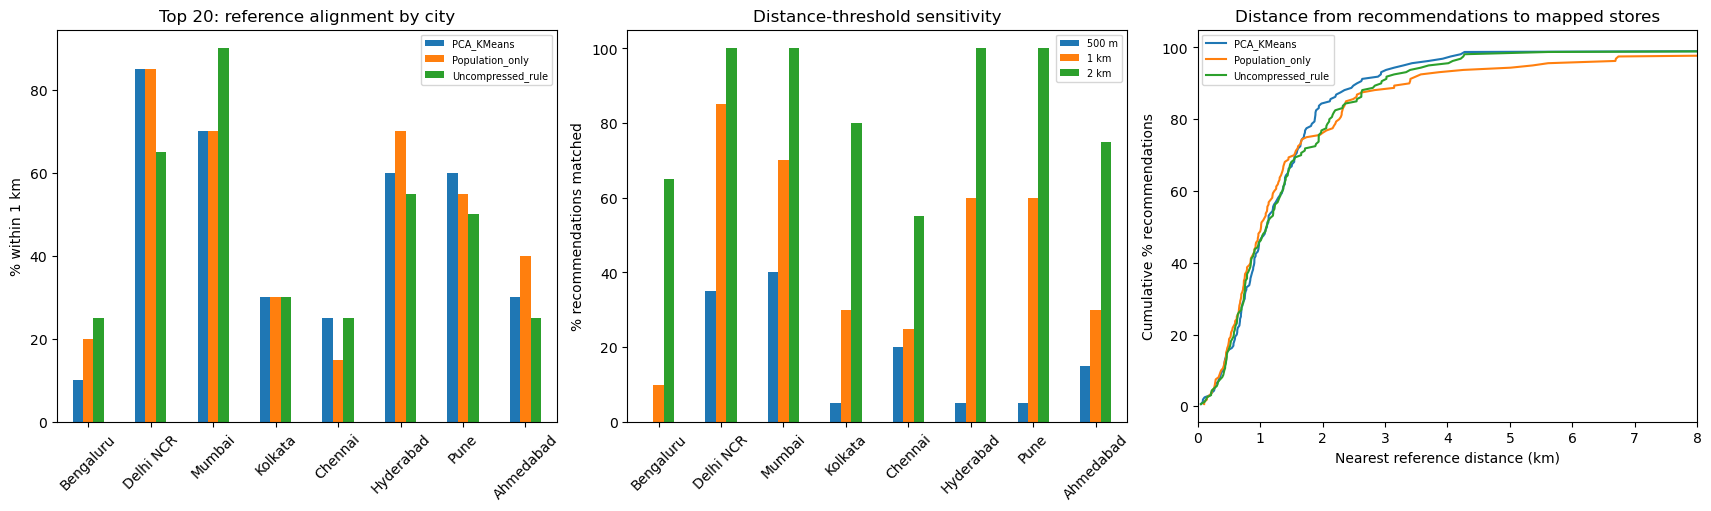

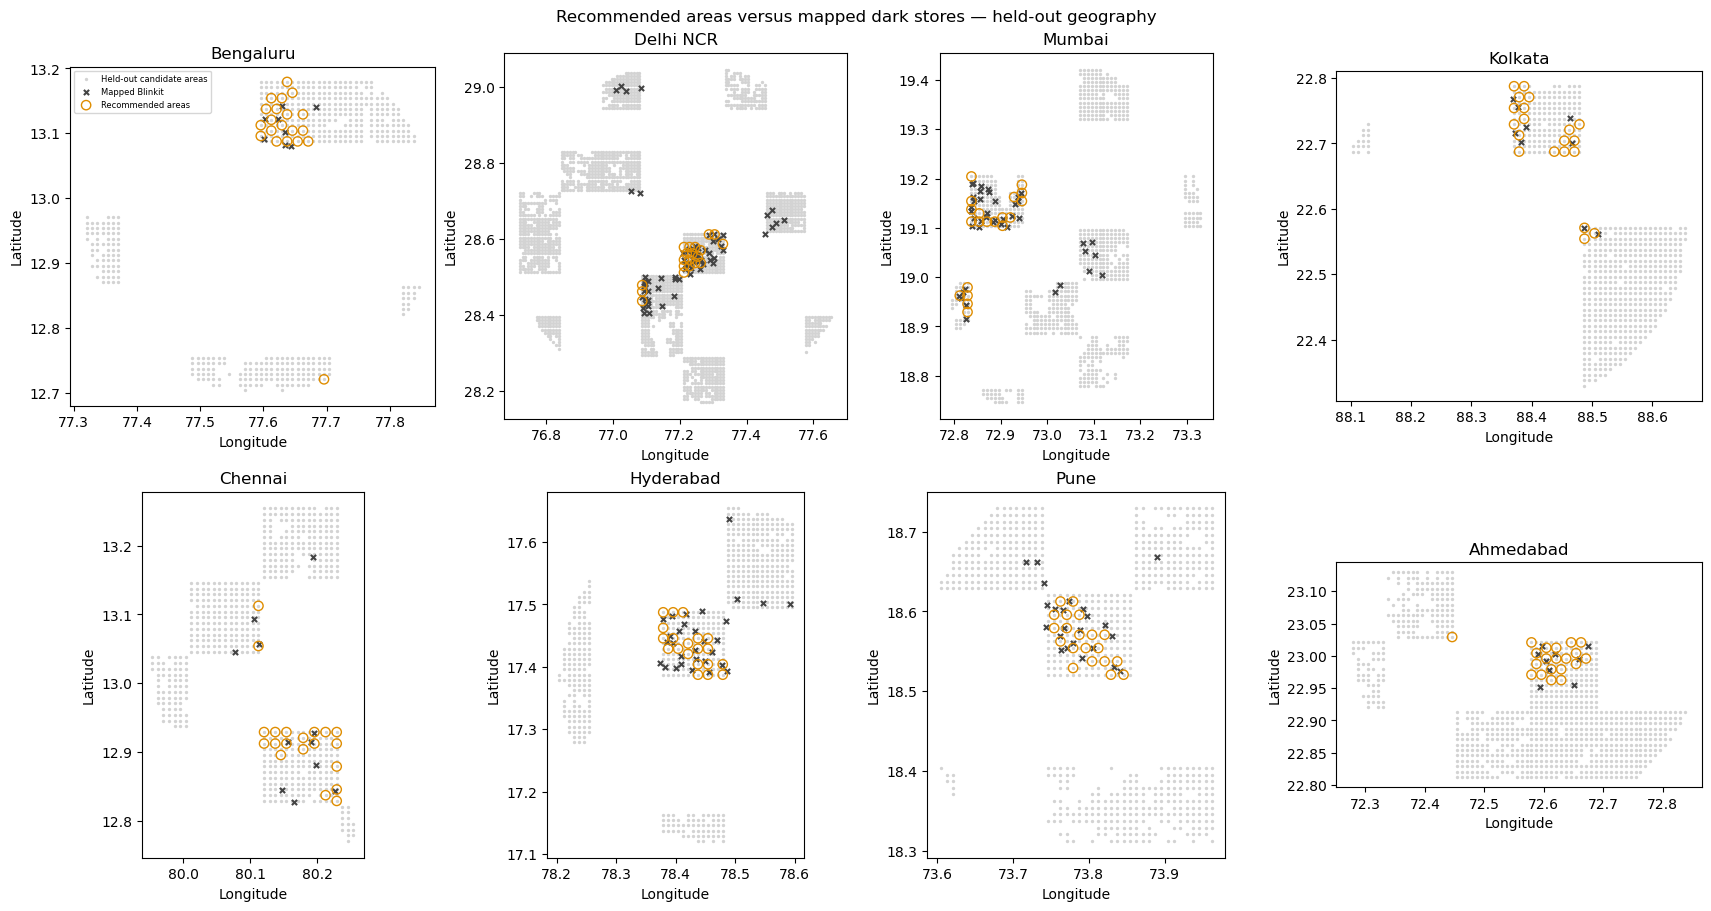

In [6]:
# PCA and cluster diagnostics, matching a straightforward segmentation workflow.
fig,ax=plt.subplots(2,2,figsize=(13,9),layout='constrained')
ax[0,0].plot(range(1,9),cumulative*100,marker='o');ax[0,0].axhline(90,ls='--',color='gray')
ax[0,0].axvline(prep['n_components'],ls=':',color='orange');ax[0,0].set(title='One pooled PCA: variance retained',xlabel='Components',ylabel='Cumulative variance (%)')
ax[0,1].plot(selection.k,selection.inertia,marker='o');ax[0,1].set(title='Elbow diagnostic',xlabel='K',ylabel='Inertia')
ax[1,0].plot(selection.k,selection.silhouette,marker='o');ax[1,0].axvline(K,color='orange',ls='--');ax[1,0].set(title=f'One shared K = {K}',xlabel='K',ylabel='Training silhouette')
for cid in range(K):
    mask=assigned.cluster.to_numpy()==cid
    ax[1,1].scatter(Xall[mask,0],Xall[mask,1],s=2,alpha=.25,label=names[cid])
ax[1,1].set(title='All eight cities in the same PCA space',xlabel='PC1',ylabel='PC2');ax[1,1].legend()
fig.savefig(ROOT/'reports/model_evaluation.png',dpi=140);plt.show()
fig=plt.figure(figsize=(10,7),layout='constrained');ax=fig.add_subplot(111,projection='3d')
sample=np.random.default_rng(SEED).choice(len(Xall),min(6000,len(Xall)),replace=False)
for cid in range(K):
    ix=sample[assigned.cluster.to_numpy()[sample]==cid]
    ax.scatter(Xall[ix,0],Xall[ix,1],Xall[ix,2],s=4,alpha=.4,label=names[cid])
ax.set(xlabel='PC1',ylabel='PC2',zlabel='PC3',title='Combined-city cluster segmentation');ax.legend()
fig.savefig(ROOT/'reports/pca_clusters.png',dpi=140);plt.show()
# Baselines, threshold sensitivity and distance curves.
fig,ax=plt.subplots(1,3,figsize=(17,5),layout='constrained')
pivot=baselines.pivot(index='city',columns='method',values='hit_1km').reindex(list(CITIES))
pivot.mul(100).plot.bar(ax=ax[0],rot=45);ax[0].set(title='Top 20: reference alignment by city',ylabel='% within 1 km',xlabel='');ax[0].legend(fontsize=7)
alignment.set_index('city')[['hit_500m','hit_1km','hit_2km']].mul(100).plot.bar(ax=ax[1],rot=45)
ax[1].set(title='Distance-threshold sensitivity',ylabel='% recommendations matched',xlabel='');ax[1].legend(['500 m','1 km','2 km'],fontsize=7)
for method,dist in distance_records.items():
    values=np.sort(np.concatenate(dist));ax[2].plot(values,np.arange(1,len(values)+1)/len(values)*100,label=method)
ax[2].set(title='Distance from recommendations to mapped stores',xlabel='Nearest reference distance (km)',ylabel='Cumulative % recommendations',xlim=(0,8));ax[2].legend(fontsize=7)
fig.savefig(ROOT/'reports/store_comparison.png',dpi=140);plt.show()
# Geographic small multiples; coordinates are area anchors, not proposed properties.
fig,axes=plt.subplots(2,4,figsize=(17,9),layout='constrained')
for ax,city in zip(axes.flat,CITIES):
    t=assigned[(assigned.city==city)&assigned.split.eq('test')]
    st=test_store_points[city];s=shortlist_results[shortlist_results.city==city]
    ax.scatter(t.longitude,t.latitude,c='lightgray',s=2,label='Held-out candidate areas')
    ax.scatter(st[:,1],st[:,0],c='#444444',s=14,marker='x',label='Mapped Blinkit')
    ax.scatter(s.longitude,s.latitude,facecolors='none',edgecolors='#df8d00',s=45,label='Recommended areas')
    ax.set(title=city,xlabel='Longitude',ylabel='Latitude',aspect=1/np.cos(np.radians(CITIES[city][0])))
axes.flat[0].legend(fontsize=6)
fig.suptitle('Recommended areas versus mapped dark stores — held-out geography')
fig.savefig(ROOT/'reports/location_comparison.png',dpi=140);plt.show()
shortlist_results.to_csv(ROOT/'reports/location_ranking.csv',index=False)
baselines.to_csv(ROOT/'reports/baseline_comparison.csv',index=False)

# Report and conclusions



In [7]:
def table(frame): return frame.to_html(index=False,float_format=lambda x:f'{x:.3f}',border=0)
def figure(name):
    return '<img src="data:image/png;base64,'+base64.b64encode((ROOT/'reports'/name).read_bytes()).decode()+'">'
retained=float(cumulative[prep['n_components']-1])
macro=baselines.groupby('method')[['hit_1km','store_coverage_2km','median_distance_km','reference_auroc','reference_average_precision']].mean().reset_index()
model_hit=float(macro.loc[macro.method.eq('PCA_KMeans'),'hit_1km'].iloc[0])
random_hit=float(alignment.random_hit_1km_mean.mean())
feature_table=pd.DataFrame({'feature':FEATURES,'meaning':['Residents per km²','Modeled residents within 2 km','Mapped food objects within 2 km','Mapped education objects within 2 km','Mapped healthcare objects within 2 km','Mapped retail objects within 2 km','Mapped transit objects within 2 km','Mapped Zepto/Instamart stores within 2 km'],'priority_weight':PRIORITY_WEIGHTS})
html=f'''<!doctype html><html><head><meta charset="utf-8"><title>Combined-city PCA–KMeans report</title><style>body{{font:16px/1.65 system-ui;max-width:1150px;margin:40px auto;padding:0 25px;color:#23343c}}h2{{margin-top:36px;color:#22636b}}table{{display:block;overflow:auto;border-collapse:collapse;font-size:13px}}td,th{{padding:9px;border-bottom:1px solid #ddd;white-space:nowrap}}th{{background:#eef4f3}}img{{max-width:100%}}.box{{padding:20px;background:#eef4f3}}code{{background:#eee}}</style></head><body>
<h1>One combined-city PCA–KMeans model</h1>
<div class="box">{len(assigned):,} areas · eight metros · eight features → {prep['n_components']} PCA components · <b>one shared K = {K}</b> · retained variance <b>{retained:.2%}</b></div>
<h2>1. Simple project workflow</h2><p>Combine all eight cities → explore features → log transform and scale → PCA → one KMeans model → profile and rank clusters → rank candidate areas → compare with independently mapped Blinkit stores. There is one fitted preprocessing pipeline and one fitted clustering model for the entire dataset. City names and coordinates are identifiers/evaluation fields, not clustering inputs. Unlike independent city models, a cluster has the same definition in every city.</p>
<h2>2. Dataset and features</h2>{table(feature_table)}
<p>The study includes Bengaluru, Delhi NCR, Mumbai, Kolkata, Chennai, Hyderabad, Pune and Ahmedabad. Each row is a roughly 1 km population grid cell with at least 100 estimated residents. Windows are circles of 50 km around Delhi, 40 km around Mumbai and 30 km around other centers; these are not official metro boundaries. Full data, city, coordinates and dates are preserved in the CSV.</p>
<p>WorldPop R2025A provides modeled 2026 population, not census counts. OSM amenity snapshots are October 2026 except Hyderabad July 2026. The independent dark-store reference and competitors are March 2026. Counts are mapped objects, not measured footfall. Two-kilometer catchments use straight-line distance and whole-cell population aggregation, not travel-time isochrones. Income, traffic speeds, congestion, rent and property availability are unavailable and have not been invented. Source metadata are in data/sources.json. This notebook starts from the previously extracted feature table.</p>
{figure('eda.png')}
<h2>3. Preparation and PCA retention</h2><p>Fit 1st/99th-percentile caps, log1p transformation, StandardScaler and PCA using the pooled training rows from all cities. Caps reduce extreme-value influence but can suppress genuine extremes. Scaling prevents the original units from dominating Euclidean distance. PCA combines correlated features into new component scores. KMeans uses only PC1 through PC{prep['n_components']}, not the original eight columns.</p>
<p>Retain three components if they explain at least 90% of training variance; otherwise retain four and report the actual result. This run retains <b>{retained:.2%}</b> using <b>{prep['n_components']}</b> components. This is variance of capped, logged and standardized features, not percentage accuracy or original records retained. All rows remain available.</p>{table(pca_table)}<h3>Component coefficients</h3>{table(loadings.reset_index(names='feature'))}
<h2>4. One KMeans model and one K</h2><p>Use <b>K={K}</b> across all cities, fixed at the user's request for finer segmentation. Compare K=2–6 using pooled training silhouette and elbow/inertia as diagnostics. The earlier silhouette rule favors K={diagnostic_k}; K=4 is a granularity choice, not a claim of optimal silhouette or better prediction. All four clusters pass the minimum 2% training-share check. Inertia decreases with K and cannot alone justify additional clusters.</p>{table(selection)}{figure('model_evaluation.png')}{figure('pca_clusters.png')}
<h2>5. Cluster ranking and location potential</h2><p>Calculate global training percentiles for each feature. Weight population density 25%, catchment population 25%, food 10%, education 5%, healthcare 5%, retail 10%, transit 10% and low competition 10%. Reverse competition's percentile. Average this business utility within each cluster and assign priority labels in order. These assumptions are fixed before viewing Blinkit references. They are not learned profitability or validated demand weights.</p>{table(profiles)}
<p>Each area's potential index is the smooth distance-weighted average of cluster utilities: softmax of negative squared centroid distances divided by twice the squared temperature. Temperature is the median training distance to the closest centroid, floored at 0.1. The index is on a 0–100 scale, not a probability. Individual areas are ranked within city; the global cluster priority stays the same across cities. A high-priority area still requires property and operational checks.</p><h3>Cluster distribution across cities</h3>{table(city_clusters.reset_index())}<h3>Top five evaluation candidates per city</h3>{table(shortlist_results.groupby('city',sort=False).head(5))}
<h2>6. Keeping evaluation reliable without extra models</h2><p>Hold out 20% of approximately 12 km geographic blocks in each city; pool the remaining training areas into the single model. Exclude training centers within 4 km of any test center to reduce overlap of 2 km feature catchments. There are {int(assigned.split.eq('train').sum()):,} training cells, {int(assigned.split.eq('test').sum()):,} test cells and {int(assigned.split.eq('buffer_excluded').sum()):,} buffer-excluded cells. All-city assignments are exported, but only test cells enter reported comparisons. Saved model is the frozen training fit.</p>
<p>PCA is compression, not guaranteed prevention of overfitting; KMeans has no L1/L2 regularization here. Controls include a small feature set, 3–4 components, restrained K, train-only preprocessing and held-out geography. Five 80% training resamples refit preprocessing and KMeans at the chosen K/components. Mean held-out assignment stability ARI: <b>{np.mean(ari):.3f}</b>; minimum <b>{min(ari):.3f}</b>. Held-out silhouette: <b>{held_sil:.3f}</b>; Davies–Bouldin: <b>{held_db:.3f}</b>. Stability and separation are not location accuracy. Row resampling is not a spatial bootstrap. A single spatial split is used; larger cities contribute more training rows.</p>
<h2>7. Comparison with mapped real dark stores</h2><p>Blinkit coordinates are first opened after the global model and priority rule are frozen. Remove duplicate IDs/coordinates and known coordinate errors above 100 m; unknown errors remain unknown. For each city choose up to 20 held-out candidate areas at least 1.5 km apart. Compare with stores in the same test blocks. Every baseline uses the same candidates, spacing and store references. Stores outside test blocks are excluded, which can undercount matches near boundaries.</p>{table(reference_counts)}
<ul><li><b>Hit @ 500 m/1 km/2 km:</b> fraction of recommendations within that radius of a mapped test store.</li><li><b>Store coverage @ 2 km:</b> fraction of mapped test stores within 2 km of a recommendation.</li><li><b>Median nearest-store distance:</b> typical separation in kilometers; lower indicates closer alignment.</li><li><b>Reference AUROC and average precision:</b> ranking against “within 1 km of a mapped store.” Missing mapped stores are not verified negatives.</li><li><b>Random lift:</b> model hit rate divided by mean of 100 random spatially separated shortlists. Random percentiles are simulation ranges, not confidence intervals.</li></ul>
<p>Several recommendations may match the same store, so coverage is reported separately. These metrics assess retrospective geographic alignment, not future-opening accuracy. This K=4 revision reuses the previously inspected geographic holdout; treat its comparison as exploratory, not a fresh independent test of the revised choice. They do not identify whether an unmatched area is a good new expansion opportunity.</p>
{figure('location_comparison.png')}{figure('store_comparison.png')}{table(alignment)}<h3>Equal-weight city averages</h3>{table(macro)}<p>Random mean hit @ 1 km: <b>{random_hit:.1%}</b>. Global PCA–KMeans hit @ 1 km: <b>{model_hit:.1%}</b>. Compare the full baseline table rather than assuming clustering improves location selection.</p>{table(baselines)}
<h2>8. Conclusions and interview explanation</h2><p>We compressed eight features to {prep['n_components']} components with {retained:.2%} transformed variance retained and produced one consistent {K}-cluster segmentation across all metros. Priority is transparent and interpretable. Stable clusters do not automatically give superior site recommendations: use the baseline results to judge the ranking separately. The uncompressed weighted rule and population-only baseline are deliberately included to expose whether extra complexity helps.</p>
<p><b>Interview explanation:</b> “I combined geospatial population and amenity data for eight Indian metros, explored missingness and correlations, standardized eight inputs and applied PCA. I trained one KMeans model on the reduced combined-city data, used a common K=4 for actionable segmentation granularity while reporting silhouette and elbow diagnostics, and profiled clusters with an explicit priority rule. I evaluated ranked areas against an independent store-location reference using spatial holdouts, distance-based hit rates, network coverage and simple baselines. I distinguished unsupervised cluster quality from real-location alignment.”</p>
<p><b>Tools:</b> Python, Pandas, NumPy, Matplotlib, scikit-learn StandardScaler/PCA/KMeans/BallTree and metrics, SciPy, Jupyter and joblib. No second clustering algorithm is needed to satisfy this project; the profile/ranking tables provide interpretation.</p>
<p><b>Limits:</b> modeled rather than enumerated population, incomplete OSM coverage, dated unofficial stores, circular study boundaries, unknown operating status, assumptions in weights and a single split. October amenities compared with March stores are a temporal mismatch: this is retrospective alignment. Better future evidence would include verified store opening dates, pre-opening covariates, property feasibility, delivery times and subsequent orders/profit. Do not tune repeatedly against this holdout and still call it independent.</p>
<h2>9. Files and reproducibility</h2><p>One notebook contains the entire analysis. data/ holds frozen inputs and source metadata; model/global_model.joblib contains the single pooled model and preprocessing; model/area_assignments.csv includes PCs' derived cluster, priority, potential rank and split; reports/ contains this report, plots, metrics and ranking tables; guide/ explains execution. No city models or second clustering pipeline are included. The supplied customer-segmentation notebook was used as a workflow reference and was not modified.</p>
<p>All features are finite/nonnegative and zone IDs unique. No Blinkit count or location enters the feature vector. Shared model preprocessing and cluster IDs are identical across cities. Fixed seed is 42. Only load trusted joblib files.</p>
<h2>Sources</h2><p><a href="https://hub.worldpop.org/project/categories?id=3">WorldPop</a> · <a href="https://www.openstreetmap.org/copyright">OpenStreetMap contributors / ODbL</a> · <a href="https://github.com/jatin-dot-py/darkstores">Independent dark-store reference</a>. No explicit data license was found for the store reference; verify permission before publishing those data. Exact population URL and snapshot dates are in data/sources.json.</p></body></html>'''
(ROOT/'reports/model_report.html').write_text(html)
print('GLOBAL MODEL: K=',K,'PCs=',prep['n_components'],'variance=',retained,'ARI=',np.mean(ari))
print(macro.to_string(index=False));print('Random hit @ 1km:',random_hit)

GLOBAL MODEL: K= 4 PCs= 4 variance= 0.9169516031432794 ARI= 0.9925179115508165
           method  hit_1km  store_coverage_2km  median_distance_km  reference_auroc  reference_average_precision
       PCA_KMeans  0.46250            0.727328            1.184448         0.927849                     0.529179
  Population_only  0.48125            0.804738            1.173423         0.908747                     0.486854
Uncompressed_rule  0.45625            0.717823            1.214953         0.922986                     0.494265
Random hit @ 1km: 0.09362500000000001
